In [2]:
import pathlib
import string
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib as mpl

import helpers
import plot_helpers

letters = string.ascii_lowercase

extra_figs = pathlib.Path('/work/bb1153/b382635/plots/model_paper/grl_submission/figures/paper_supplementary_04A')
extra_figs.mkdir(parents=True, exist_ok=True)

dpi = 200
ext = 'jpg'
fs = 12

In [3]:
# load data

datadir = pathlib.Path('/work/bb1153/b382635/plots/model_paper/grl_resubmission/data/statistics_L2')
ds_flist = sorted(list(datadir.glob('*.nc')))
li = [xr.open_dataset(f) for f in ds_flist]
ds_all = xr.concat(li, dim='system')
print(ds_all.system.size, 'DCCs loaded')

1700 DCCs loaded


In [4]:
# filter data, matching 04.supplementary_figures.ipynb / 06.resubmission_figures.ipynb

gsystems = ds_all.max_CMF.dropna('system').system
ds = ds_all.sel(system=gsystems)
ds = ds.where(ds.lifestages_valid).dropna('system', how='all')
print(ds.system.size, 'DCCs with a valid lifecycle')

# two metrics share a long_name upstream ("Maximum updraft") - disambiguate for axis titles below
ds['max_w_ABH'].attrs['long_name'] = 'Maximum updraft at ABH'
ds['max_w'].attrs['long_name'] = 'Maximum updraft over all levels'

1615 DCCs with a valid lifecycle


In [5]:
# quartile colour map (total_CMT, Section 1) and the four group comparisons (Sections 1-3)

CMAP = mpl.colors.ListedColormap(plt.get_cmap('Reds')(np.linspace(.25, 1, 265)))
key = 'total_CMT'
thresholds = (0.25, 1, 2.5)

toi_hour = xr.DataArray(pd.to_datetime(ds.TOI.values).hour, dims='system', coords={'system': ds.system})
is_night = (toi_hour < 6) | (toi_hour >= 18)
is_afternoon = (toi_hour >= 12) & (toi_hour < 18)
abh_median = ds.ABH.median()

comparisons = {
    'land_vs_ocean': [('land', ds.ocean_fraction < 0.5), ('ocean', ds.ocean_fraction >= 0.5)],
    'isolated_vs_complex': [('isolated', ds.category == 'isolated'), ('complex', ds.category == 'organised')],
    'night_vs_afternoon': [('night', is_night), ('afternoon', is_afternoon)],
    'low_vs_high_ABH': [('low ABH', ds.ABH >= abh_median), ('high ABH', ds.ABH < abh_median)],
}

# fixed colour pair per comparison, used everywhere that comparison appears (Sections 2-3)
comparison_colors = {
    'land_vs_ocean': ('darkgreen', 'darkblue'),
    'isolated_vs_complex': ('crimson', 'teal'),
    'night_vs_afternoon': ('darkorange', 'purple'),
    'low_vs_high_ABH': ('grey', 'black'),
}

for name, groups in comparisons.items():
    sizes = ', '.join(f"{gname}={int(gmask.sum())}" for gname, gmask in groups)
    print(f"{name}: {sizes}")

land_vs_ocean: land=376, ocean=1239
isolated_vs_complex: isolated=1166, complex=449
night_vs_afternoon: night=809, afternoon=471
low_vs_high_ABH: low ABH=808, high ABH=807


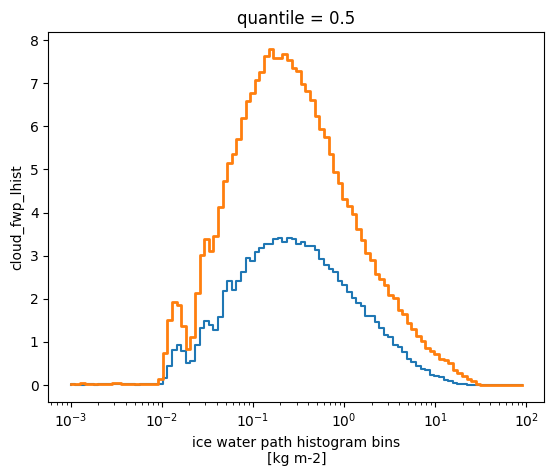

In [81]:
d = ds.where(ds.category=='isolated')

d1 = ds.cloud_fwp_lhist.where(d.total_CMT_l60 < d.total_CMT.quantile(.5))
d1 = (d1.sum('system')/d1.system.size)
d1.plot.step()
d2 = ds.cloud_fwp_lhist.where(d.total_CMT_l60 > d.total_CMT.quantile(.5))
d2 = (d2.sum('system')/d2.system.size)
d2.plot.step(lw=2)

plt.xscale('log')



In [78]:
sokol = xr.open_dataset('/home/b/b382635/s/my_notebooks/model_paper/grl_submission/scripts/rcemip_iwp-resolved_statistics.nc')
import scipy

In [96]:
((d2 - d1)).sel(lbins=slice(None,0.2)).sum()

<xarray.DataArray 'cloud_fwp_lhist' ()> Size: 8B
array(60.74241486)
Coordinates:
    quantile  float64 8B 0.5

In [97]:
((d2 - d1)).sel(lbins=slice(0.2,None)).sum()

<xarray.DataArray 'cloud_fwp_lhist' ()> Size: 8B
array(73.60743034)
Coordinates:
    quantile  float64 8B 0.5

AttributeError: Line2D.set() got an unexpected keyword argument 'k'

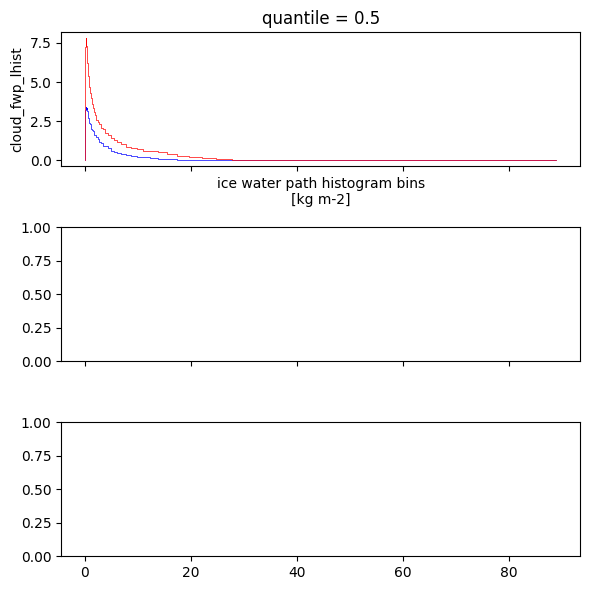

In [100]:
fig, axs = plt.subplots(3,1,figsize=(6,6),layout='tight',sharex=1)

ax = axs[0]
d1.plot.step(ax=ax, lw=.5, c='b')
d2.plot.step(ax=ax, lw=.5, c='r')
frac_change = ((d2 - d1)) #/ (d1.where(d1>.1)))
frac_change.plot.step(ax=ax, k='k')

ax = axs[1]
cre_data = sokol.ncre.mean('model').sel(SST=300)
cre_data['fwp'] = cre_data.fwp * 1e-3
cre_data.plot(ax=ax, c='k')
ax.axhline(0,c='k',lw=.5)

ax = axs[2]
x, y = cre_data.fwp, cre_data.values
xnew = ds.lbins
f = scipy.interpolate.interp1d(x, y, bounds_error=False)
cre_change = f(xnew) * (d2 - d1)
cre_change.plot(ax=ax, c='k')
ax.text(.5,.8,cre_change.sum().item(),transform=ax.transAxes)
ax.axhline(0,c='k',lw=.5)

for ax in axs:
    ax.set_xscale('log')
    ax.set_xlabel("IWP [kg m-2]")
    ax.set_xlim(1e-3,1e2)
    ax.axvline(0.2, c='k', lw=.5)

### Section 1 — Lifecycle evolution, by `total_CMT` quartile, split by group

Four panels: (a) anvil area, (b-d) thick anvil area exceeding IWP thresholds of 0.25, 1 and 2.5 kg m$^{-2}$, each
against normalised lifetime. Four lines per panel coloured by `total_CMT` quartile (as in Figure 2 of
`06.resubmission_figures.ipynb`, but simplified: no percentage-increase annotation, since that isn't needed for
a group comparison). One figure per group comparison, with linestyle distinguishing the two groups; the quartiles
of `total_CMT` are computed *within* each group separately, not on the pooled population.

In [9]:
def lifecycle_comparison_figure(ds, groups, key='total_CMT_l60', thresholds=(0.25, 1, 2.5),
                                 cmap=CMAP, linestyles=('-', '--'), fs=fs):

    nplots = len(thresholds) + 1
    fig, axs = plt.subplots(1, nplots, figsize=(nplots * 4.5, 4), layout='tight')
    axs = np.atleast_1d(axs)

    quartile_handles, quartile_labels = None, None
    group_handles, group_labels = [], []

    for gi, (gname, gmask) in enumerate(groups):
        ds_g = ds.where(gmask).dropna('system', how='all')
        df = helpers.dccs_by_intensity_metrics(ds_g, ds_g[[key]])
        grouped = helpers.group_dataset_by_intensity(
            ds_g[["cloud_area", "thick_area", "anvil_area"]], df,
            apply=lambda x: x.mean("system", keep_attrs=True),
        )[key]

        ls = linestyles[gi % len(linestyles)]
        group_handles.append(mpl.lines.Line2D([0], [0], color='k', ls=ls))
        group_labels.append(gname)

        for i, ax in enumerate(axs):
            if i == 0:
                data = grouped.cloud_area.sel(phase=["developing", "mature", "decay"])
                threshold_label = None
            else:
                threshold = thresholds[i - 1]
                data = grouped.thick_area.sel(threshold=threshold, phase=["developing", "mature", "decay"])
                threshold_label = threshold

            for j, b in enumerate(grouped.bins.values):
                color = cmap(j / 4 + 0.1)
                evolution = plot_helpers.get_evolution(data.sel(bins=b))
                line = evolution.plot(ax=ax, c=color, ls=ls, lw=1.5, label=f"{b}th")
                if gi == 0 and quartile_handles is None and j == len(grouped.bins.values) - 1:
                    quartile_handles, quartile_labels = ax.get_legend_handles_labels()

            # % increase
                if j == 0:
                    line_lo = line[0]
                if j == 3:
                    line_hi = line[0]
        
            y_lo = line_lo.get_ydata().max()
            y_hi = line_hi.get_ydata().max()
            pct = (y_hi - y_lo) / y_lo * 100
            ax.text(0.05,.8-0.075*gi,f"{pct:.0f}% ({gname})", transform=ax.transAxes)

            # plot_helpers.show_phases(ax)
            title = (rf"$\mathbf{{({letters[i]})}}$ Overall area" if i == 0
                     else rf"$\mathbf{{({letters[i]})}}$ Area where IWP > {threshold_label:.2f} kg m$^{{-2}}$")
            ax.text(0.015, 0.9, title, c='k', fontsize=fs, transform=ax.transAxes)
            ax.set_xlabel('Normalised lifetime', fontsize=fs)
            ax.set_ylabel('Area [m$^2$]' if i == 0 else None, fontsize=fs)
            ax.set_title(None)

    if quartile_handles:
        leg1 = fig.legend(quartile_handles, quartile_labels, title=rf"${key}$ percentile", fontsize=fs,
                           loc='center', bbox_to_anchor=(0.35, -0.12), ncol=4, frameon=True)
        fig.add_artist(leg1)
    if group_handles:
        fig.legend(group_handles, group_labels, fontsize=fs, loc='center',
                   bbox_to_anchor=(0.65, -0.12), ncol=len(group_handles), frameon=True, title='group')

    return fig, axs

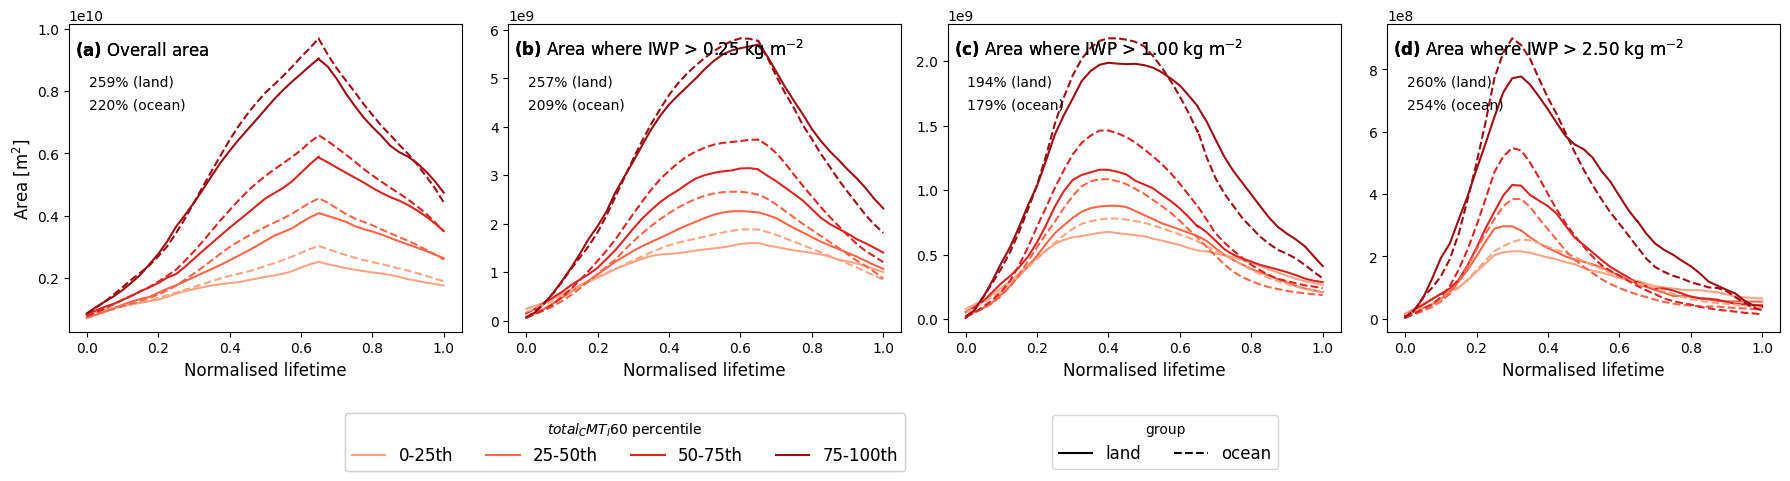

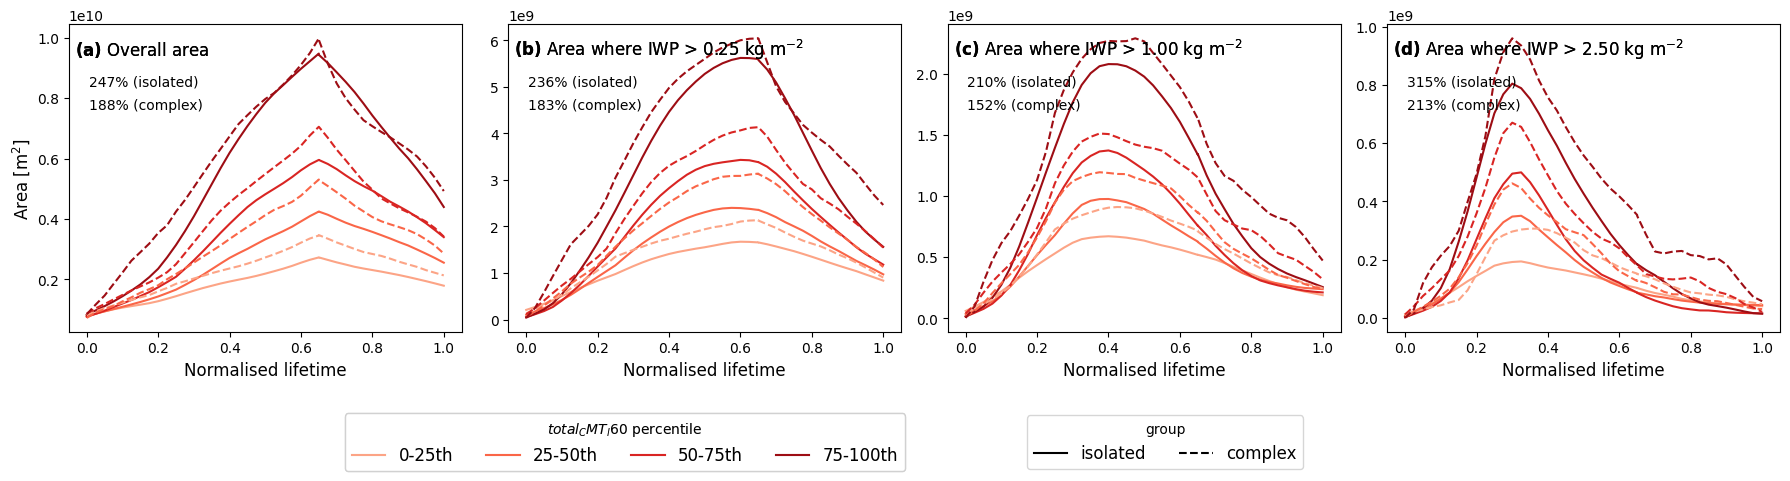

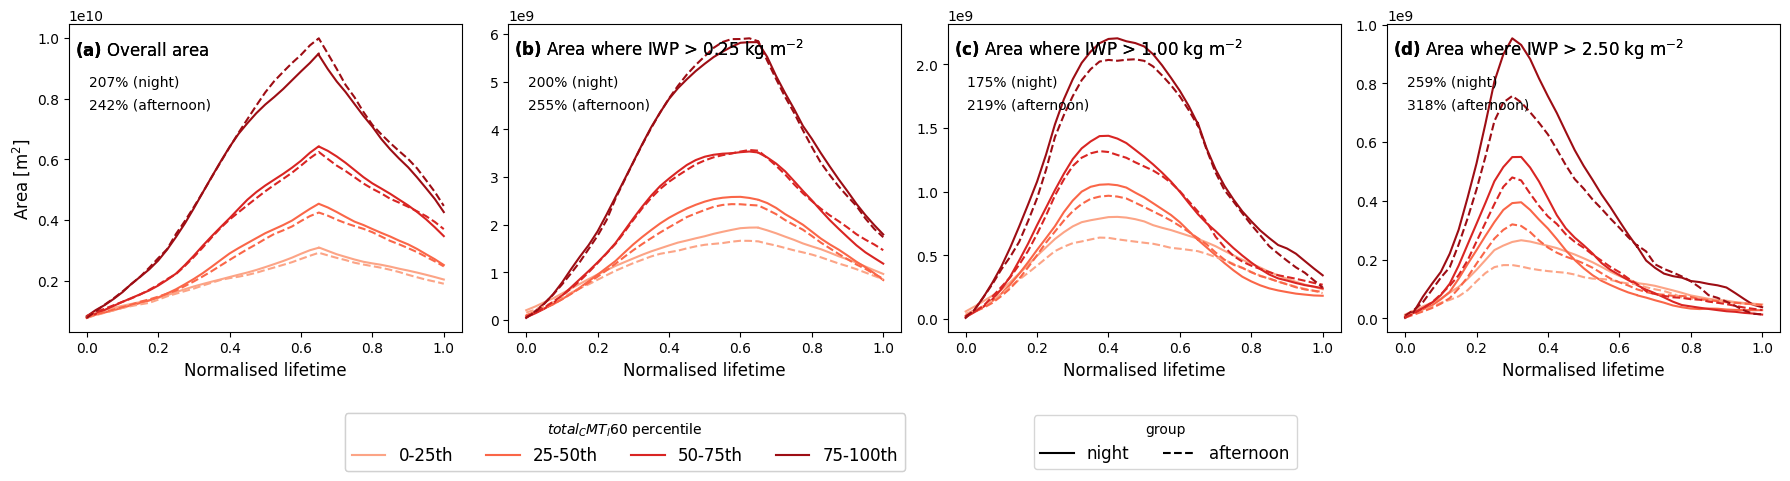

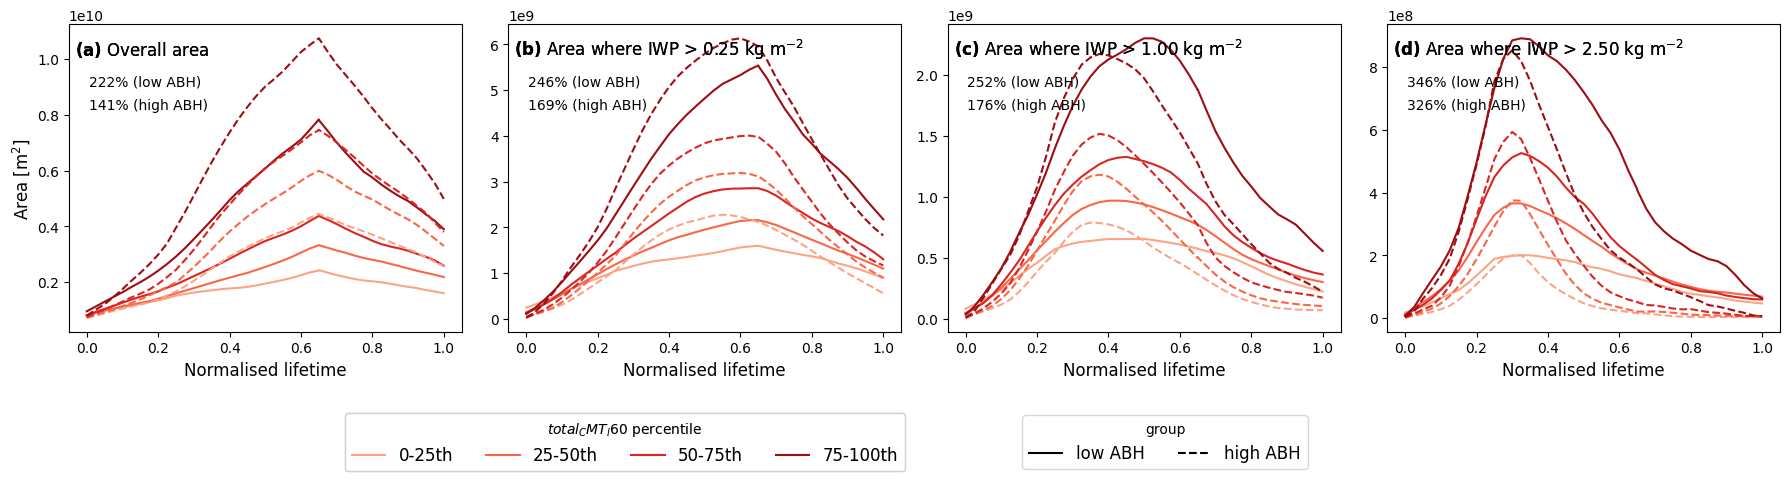

In [10]:
for name, groups in comparisons.items():
    fig, axs = lifecycle_comparison_figure(ds, groups)
    fig.savefig(extra_figs / f"fig_s1_{name}.{ext}", bbox_inches='tight', dpi=dpi)
    plt.show()

### Section 2 — Maximum area vs `total_CMT`

Scatter plots of (a) maximum anvil area and (b-d) maximum thick-anvil area (IWP > 0.25, 1, 2.5 kg m$^{-2}$)
against `total_CMT`, coloured by group (linear fit + Pearson r per group).

In [8]:
def comparison_scatter_figure(x, panels, groups, x_label, colors=('darkgreen', 'darkblue'), fs=fs):
    ''' panels: list of (data, title, ylabel) tuples, one scatter subplot per panel '''

    fig, axs = plt.subplots(1, len(panels), figsize=(4.5 * len(panels), 3.5), layout='tight')
    axs = np.atleast_1d(axs)

    for i, (y, title, ylabel) in enumerate(panels):
        ax = axs[i]
        for j, (gname, gmask) in enumerate(groups):
            valid = gmask & x.notnull() & y.notnull()
            _x = x.where(valid, drop=True)
            _y = y.where(valid, drop=True)
            if _x.size < 3:
                continue

            _, _, xline, yline, result = helpers.evaluate_predictions(_x, _y)
            c = colors[j % len(colors)]
            p_text = r"$p < 0.001$" if result.pvalue < 0.001 else rf"$p = {result.pvalue:.3f}$"
            label = rf"{gname}: $r = {result.rvalue:.2f}$ ({p_text})"
            ax.scatter(_x, _y, s=18, alpha=0.3, edgecolors="none", fc=c)
            ax.plot(xline, yline, linewidth=1.5, c=c, label=label)

        ax.legend(loc="upper left", fontsize=fs - 3)
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)
        ax.tick_params(direction="out", length=3, width=0.8)
        ax.set_xlabel(x_label, fontsize=fs)
        ax.set_ylabel(ylabel, fontsize=fs)
        ax.set_title(rf"$\mathbf{{({letters[i]})}}$ {title}", loc="left", fontsize=fs)

    return fig, axs

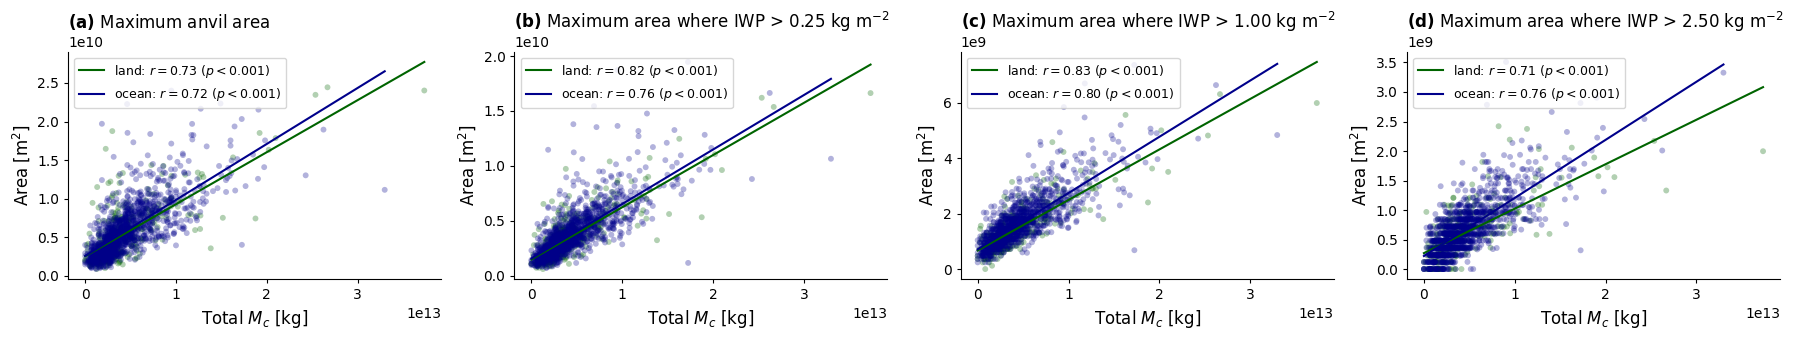

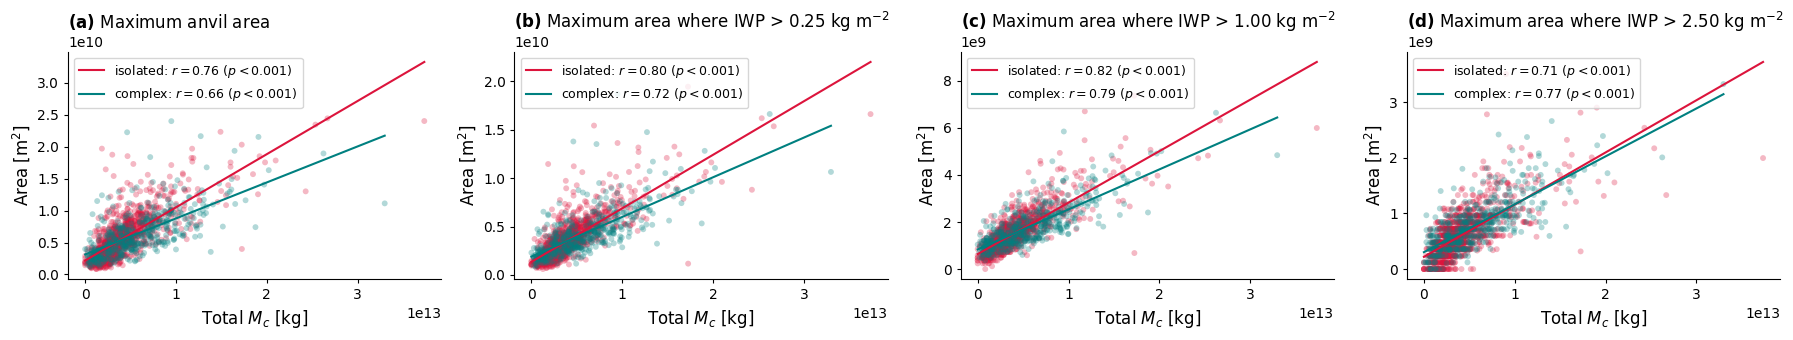

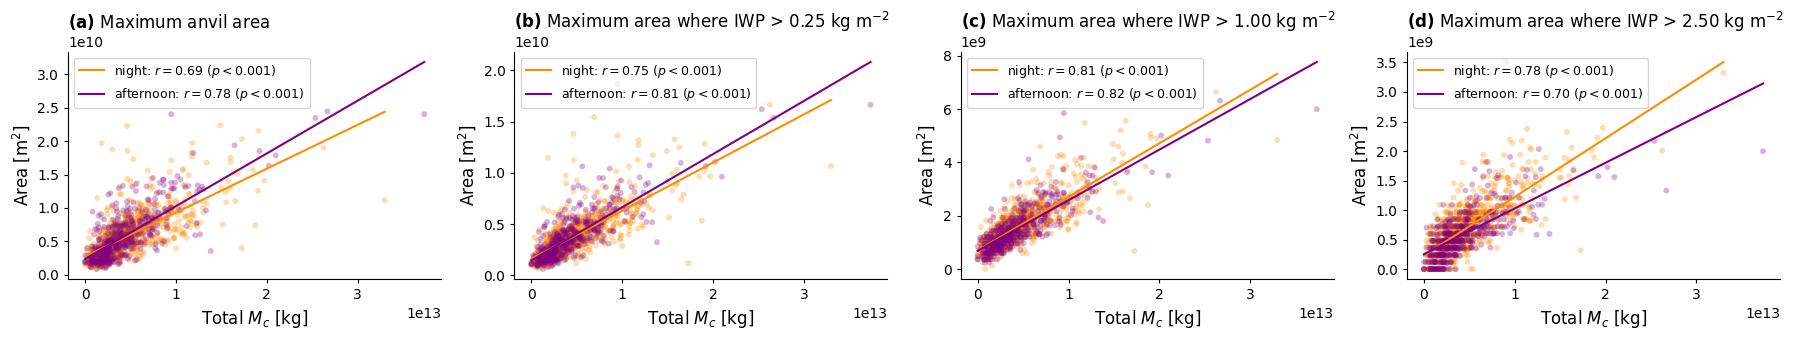

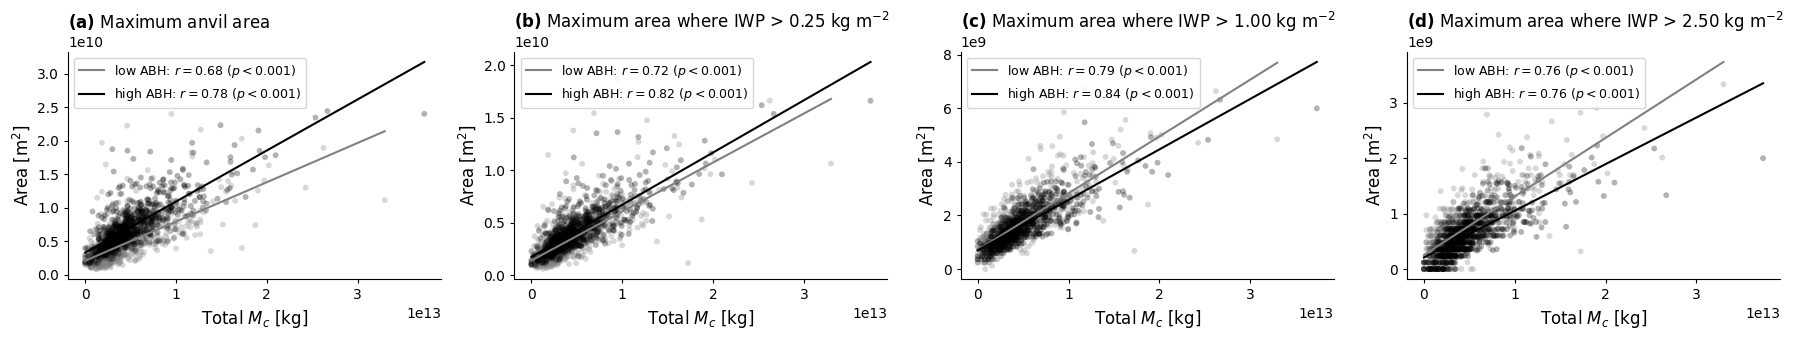

In [11]:
max_anvil_area = ds.anvil_area.max(('phase', 'interp_time'))

panels_s2 = [(max_anvil_area, "Maximum anvil area", "Area [m$^2$]")]
for t in thresholds:
    y = ds.thick_cloud_area.sel(threshold=t).max(('phase', 'interp_time'))
    panels_s2.append((y, f"Maximum area where IWP > {t:.2f} kg m$^{{-2}}$", "Area [m$^2$]"))

for name, groups in comparisons.items():
    fig, axs = comparison_scatter_figure(ds.total_CMT, panels_s2, groups, x_label=r"Total $M_c$ [kg]",
                                          colors=comparison_colors[name])
    fig.savefig(extra_figs / f"fig_s2_{name}.{ext}", bbox_inches='tight', dpi=dpi)
    plt.show()

### Section 3 — Total area vs `total_CMT`

Scatter plots of (a) total anvil area and (b-d) total thick-anvil area / total anvil area (IWP > 0.25, 1,
2.5 kg m$^{-2}$) against `total_CMT`, coloured by group.

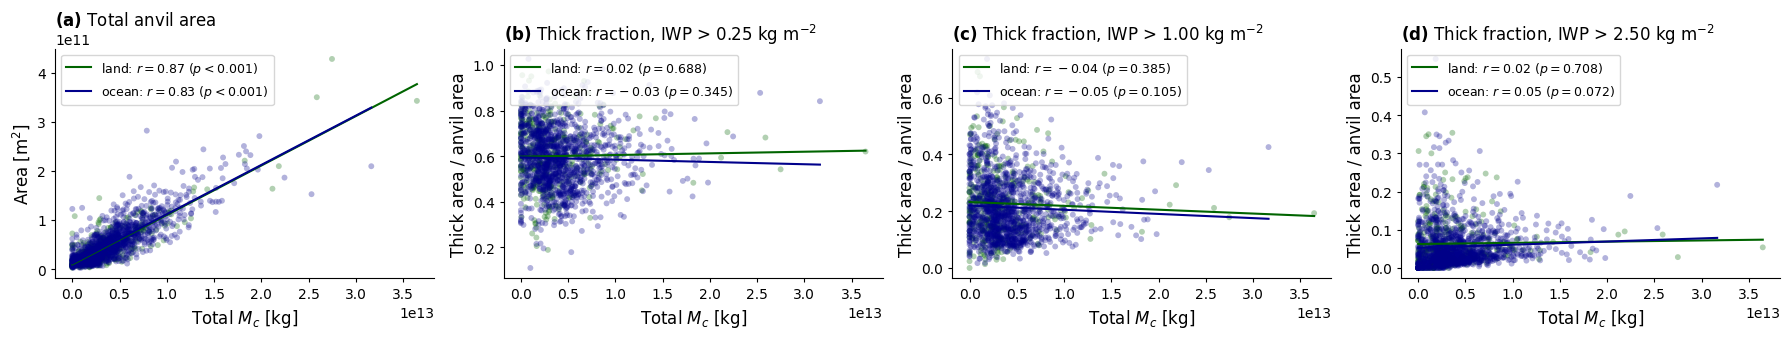

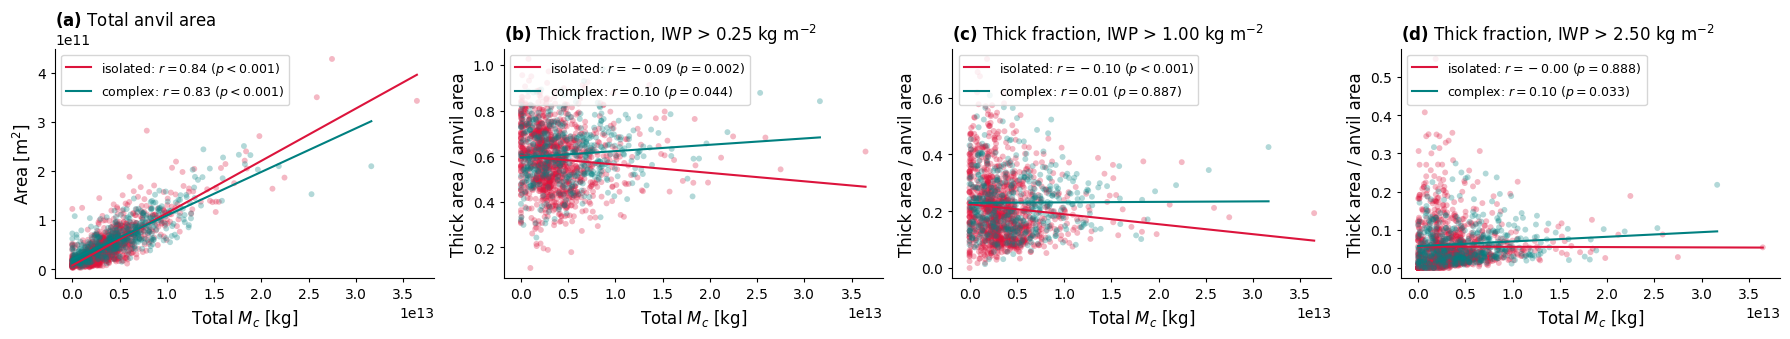

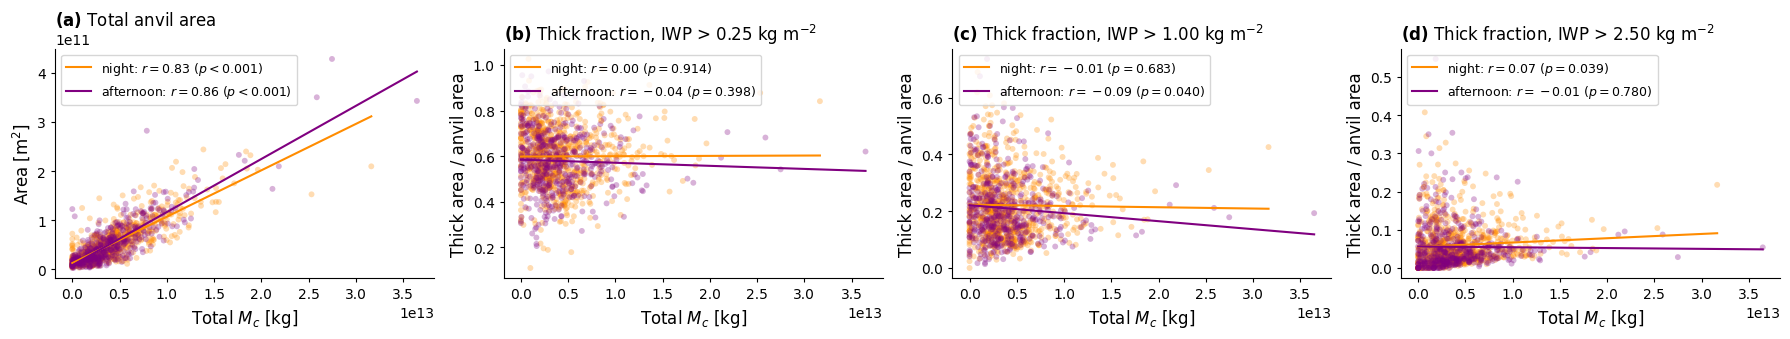

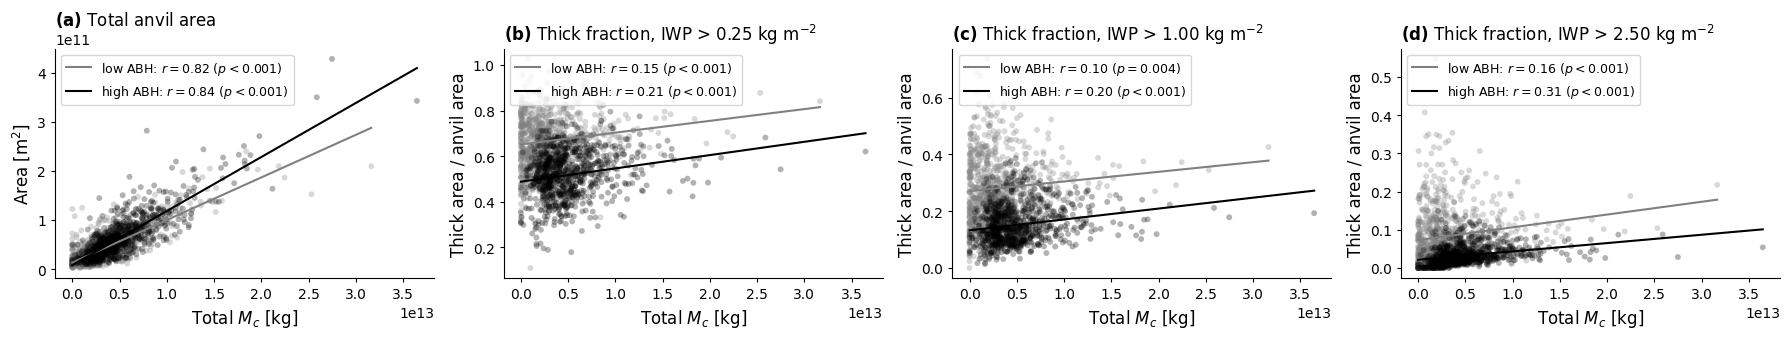

In [68]:
ratio_panels_s3 = []
for t in thresholds:
    ratio = ds.total_thick_cloud.sel(threshold=t) / ds.total_cloud_area
    ratio.attrs = dict(long_name=f"Thick area fraction (IWP > {t:.2f})", units="unitless")
    ratio_panels_s3.append(ratio)

panels_s3 = [(ds.total_anvil_area, "Total anvil area", "Area [m$^2$]")]
for t, r in zip(thresholds, ratio_panels_s3):
    panels_s3.append((r, f"Thick fraction, IWP > {t:.2f} kg m$^{{-2}}$", "Thick area / anvil area"))

for name, groups in comparisons.items():
    fig, axs = comparison_scatter_figure(ds.total_CMT_l60, panels_s3, groups, x_label=r"Total $M_c$ [kg]",
                                          colors=comparison_colors[name])
    fig.savefig(extra_figs / f"fig_s3_{name}.{ext}", bbox_inches='tight', dpi=dpi)
    plt.show()

### Section 4 — Scatter plots against physical metrics

`max_w_at_ABH` couldn't be added as a distinct metric: `core_max_w` is already reduced over `level_full` at the
`grl_fast.py` stage (it's the column-maximum updraft, not a per-level field), so there's no per-level "w" left to
index at the anvil base height. `max_w_ABH` (maximum, over time/cores, of the *mean* vertical velocity at ABH) is
used in its place for "maximum w at ABH"; `max_w` covers "maximum w over all levels".

In [14]:
metric_keys = [
    'total_CMT', 'conv_lifetime', 'max_CMT', 'mean_CMT', 'max_Ac', 'max_CMF_ABH',
    'max_w_ABH', 'max_w', 'max_core_pr', 'net_core_pr', 'cloud_tt_min_overall',
]

def metric_scatter_grid(ds, metric_keys, y, y_label, ncols=4, fs=10):
    nrows = int(np.ceil(len(metric_keys) / ncols))
    fig, axs = plt.subplots(nrows, ncols, figsize=(3 * ncols, 2.6 * nrows), layout='tight')
    axs = np.atleast_1d(axs).flatten()

    for i, key in enumerate(metric_keys):
        ax = axs[i]
        x = ds[key]
        valid = x.notnull() & y.notnull()
        _x, _y = x.where(valid, drop=True), y.where(valid, drop=True)

        if _x.size >= 3:
            _, _, xline, yline, result = helpers.evaluate_predictions(_x, _y)
            ax.scatter(_x, _y, s=14, alpha=0.5, edgecolors='none', fc='grey')
            ax.plot(xline, yline, lw=1.5, c='k')
            p_text = r"$p < 0.001$" if result.pvalue < 0.001 else rf"$p = {result.pvalue:.3f}$"
            ax.text(0.05, 0.95, rf"$r = {result.rvalue:.2f}$" + "\n" + p_text,
                    transform=ax.transAxes, ha='left', va='top', fontsize=fs - 2)

        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.tick_params(direction='out', length=3, width=0.8)
        ax.set_xlabel(x.attrs.get('units', ''), fontsize=fs)
        ax.set_ylabel(y_label, fontsize=fs)
        ax.set_title(rf"$\mathbf{{({letters[i]})}}$ {x.attrs.get('long_name', key)}", loc='left', fontsize=fs)

    for j in range(len(metric_keys), len(axs)):
        axs[j].axis('off')

    return fig, axs

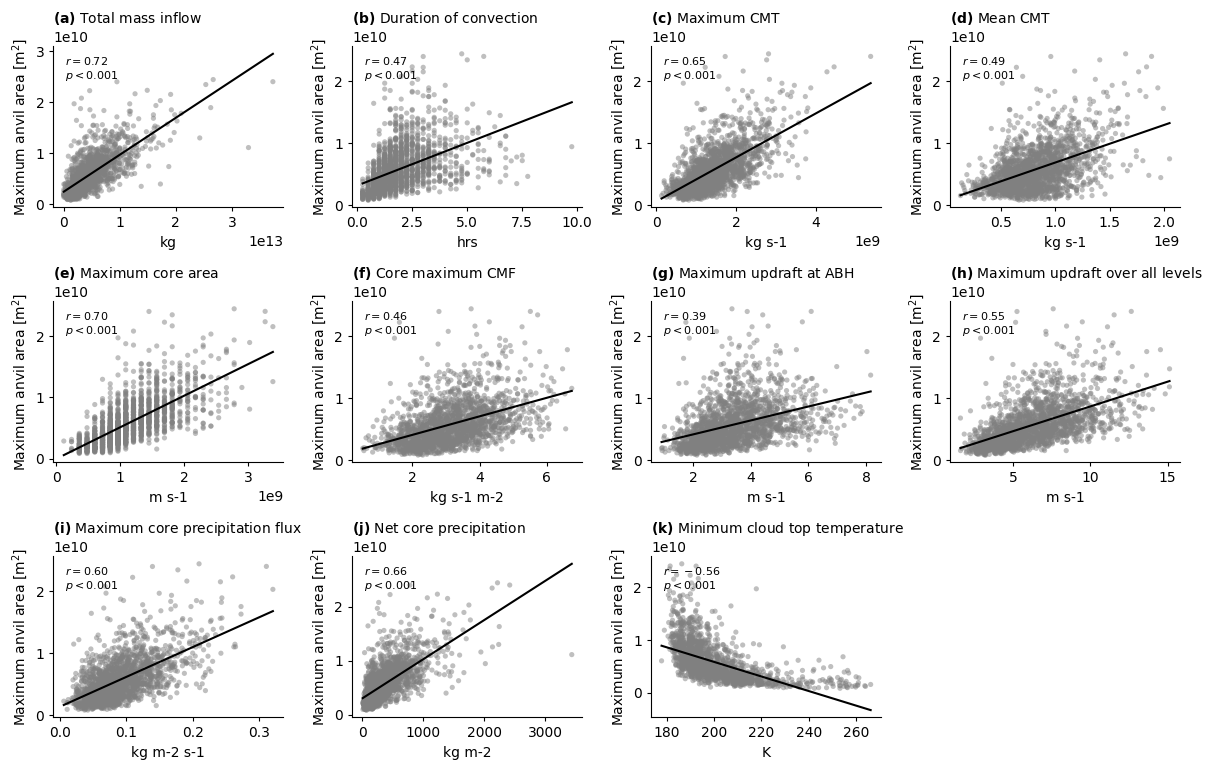

In [11]:
# maximum anvil area vs each metric

fig, axs = metric_scatter_grid(ds, metric_keys, max_anvil_area, "Maximum anvil area [m$^2$]")
fig.savefig(extra_figs / f"fig_s4_max_anvil_area.{ext}", bbox_inches='tight', dpi=dpi)
plt.show()

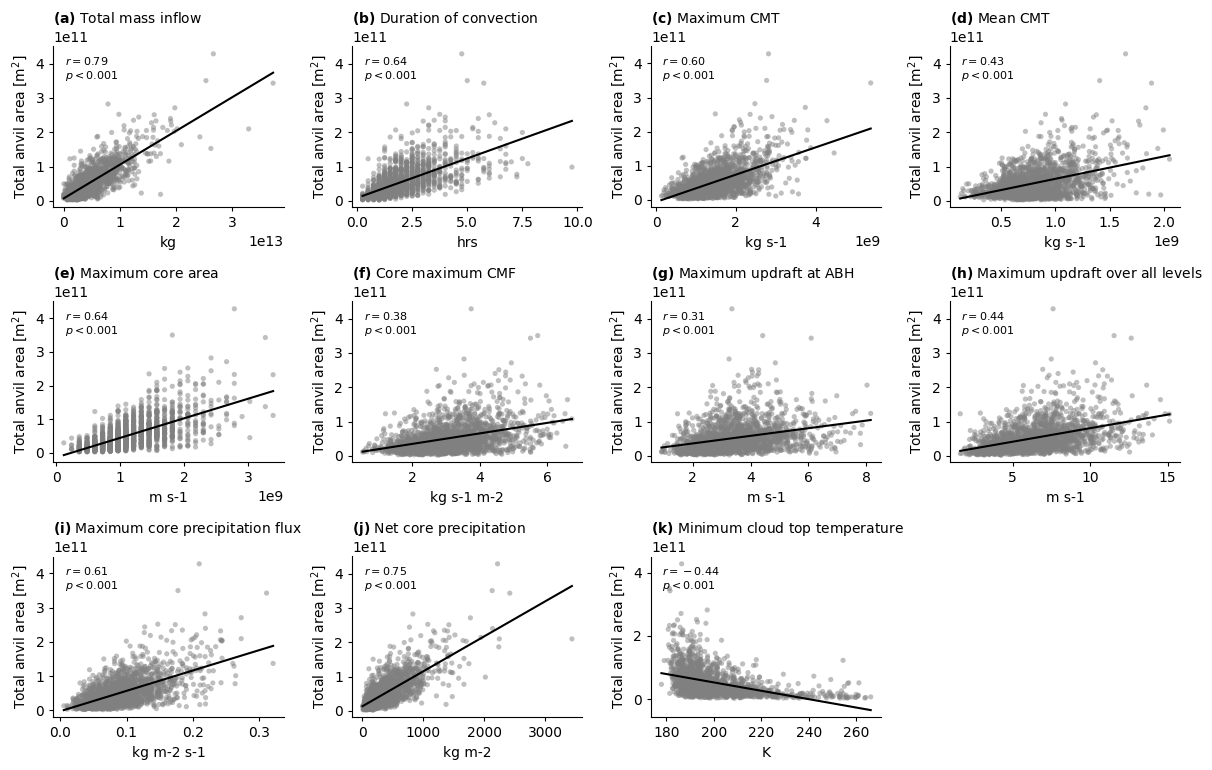

In [12]:
# total anvil area vs each metric

fig, axs = metric_scatter_grid(ds, metric_keys, ds.total_anvil_area, "Total anvil area [m$^2$]")
fig.savefig(extra_figs / f"fig_s4_total_anvil_area.{ext}", bbox_inches='tight', dpi=dpi)
plt.show()

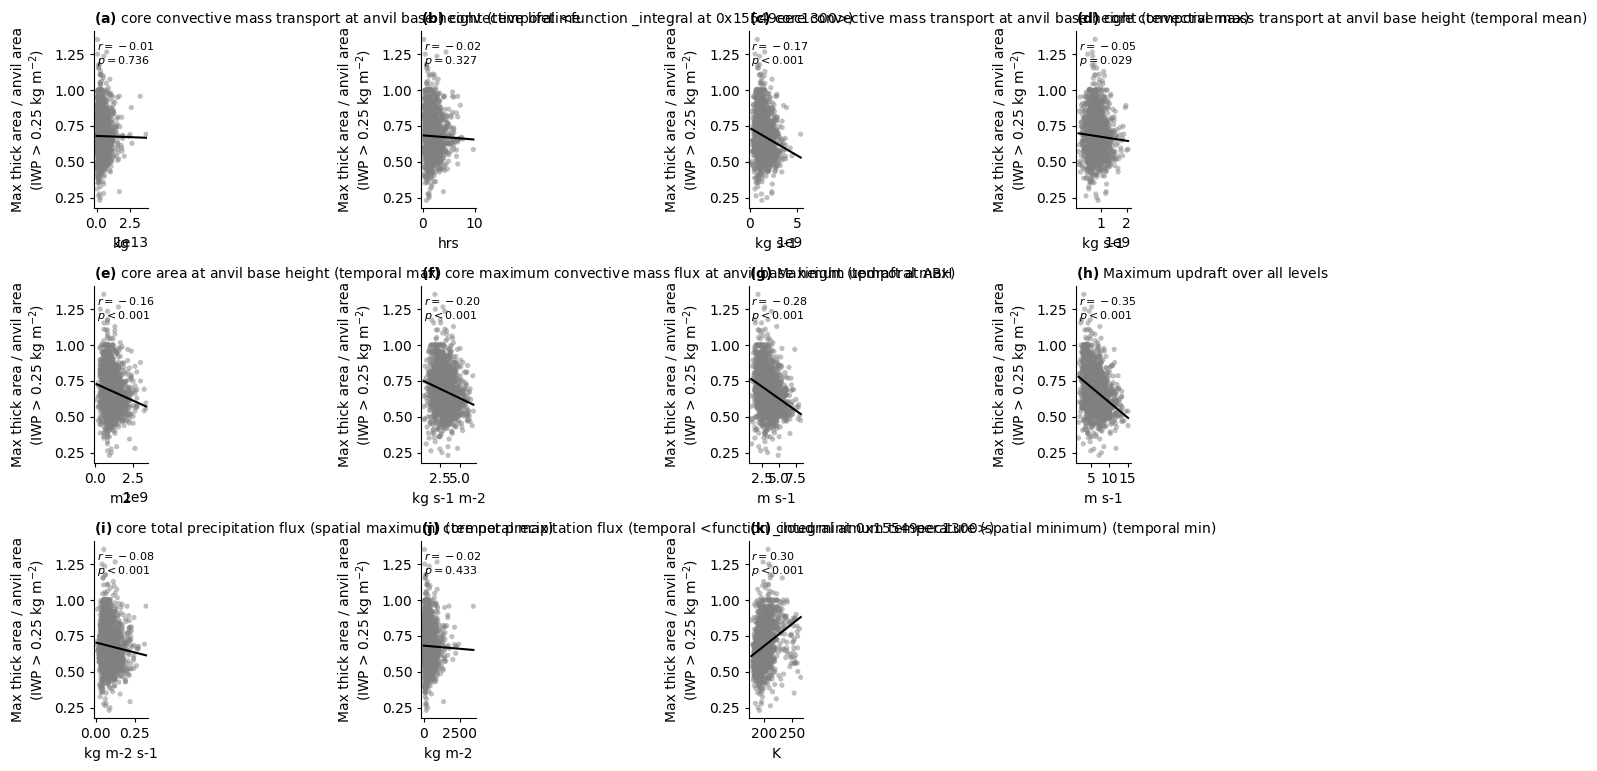

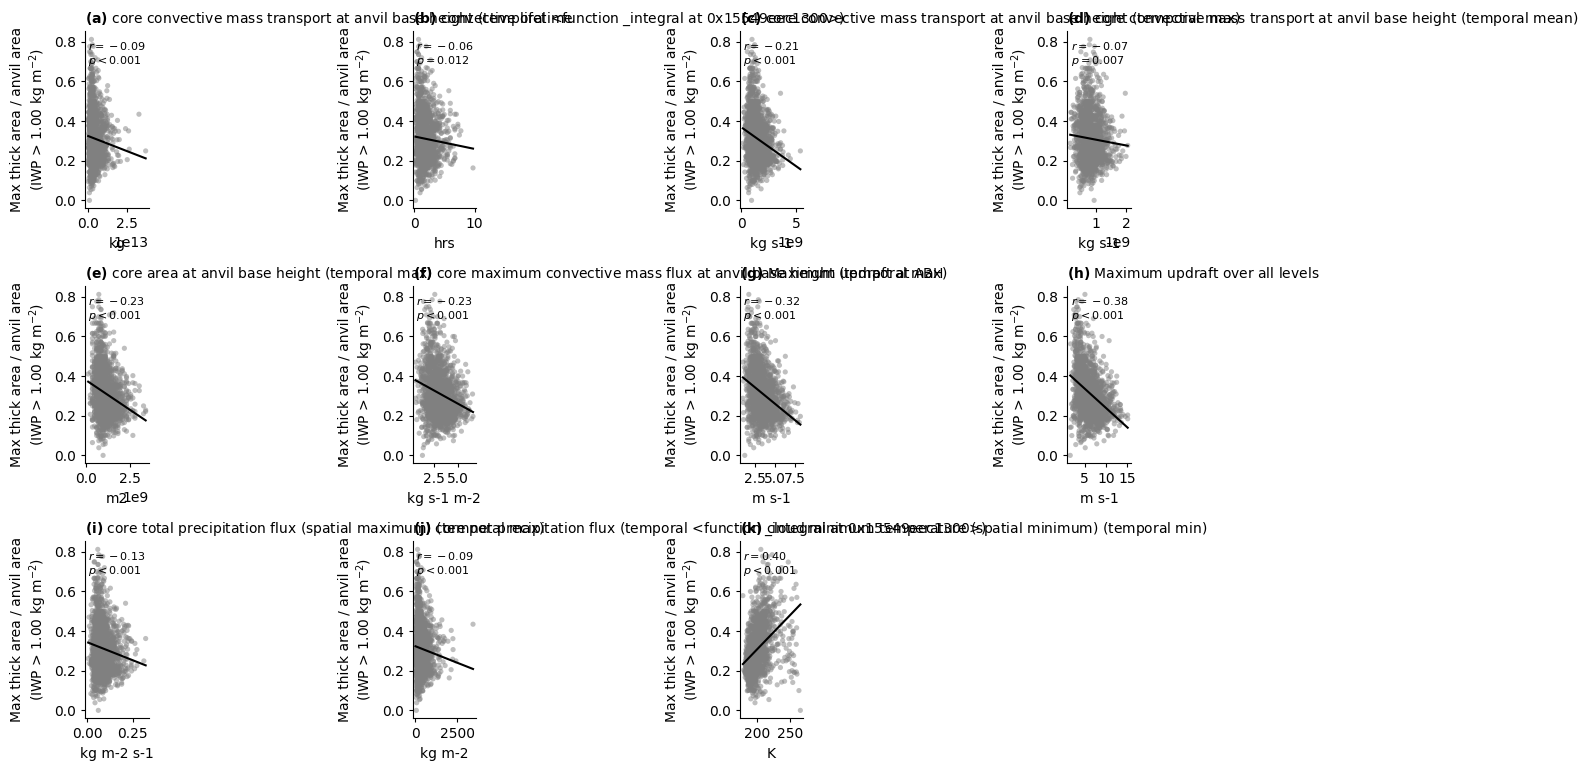

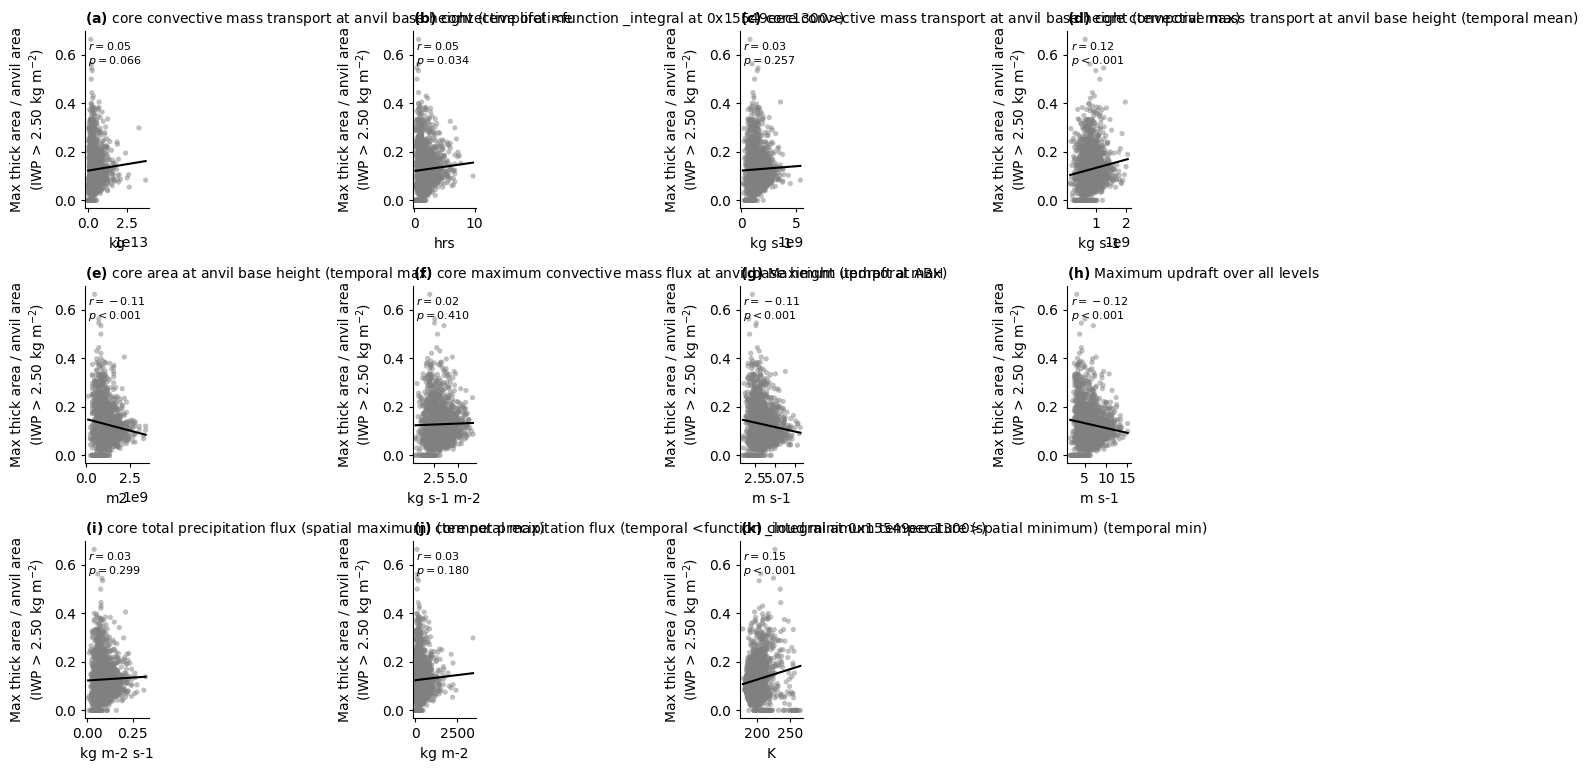

In [15]:
# max thick / overall anvil area vs each metric

max_anvil_area = ds.cloud_area.max(('phase', 'interp_time'))
max_thick_area = ds.thick_cloud_area.max(('phase', 'interp_time'))
max_ratio = max_thick_area / max_anvil_area

for t in thresholds:
    r = max_ratio.sel(threshold=t)
    fig, axs = metric_scatter_grid(ds, metric_keys, r, f"Max thick area / anvil area\n(IWP > {t:.2f} kg m$^{{-2}}$)")
    fig.savefig(extra_figs / f"fig_s4_max_thick_fraction_{str(t).replace('.', 'p')}.{ext}", bbox_inches='tight', dpi=dpi)
    plt.show()

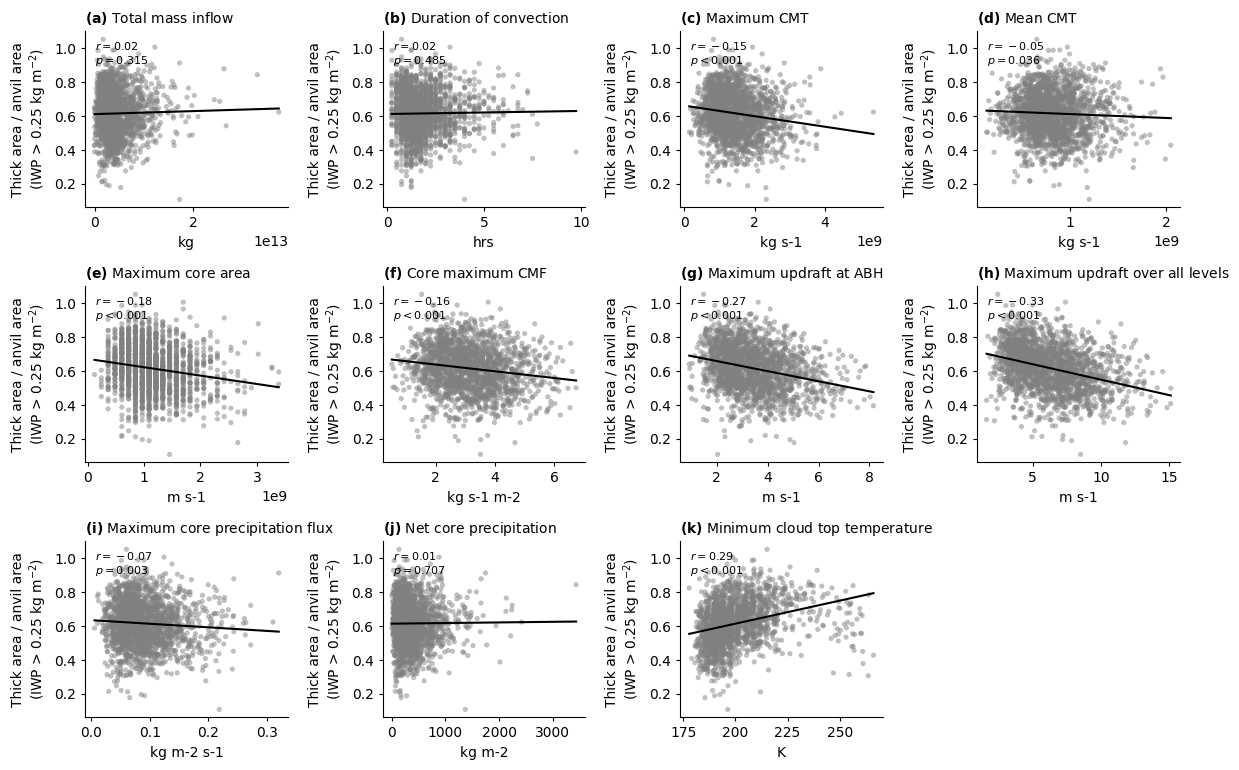

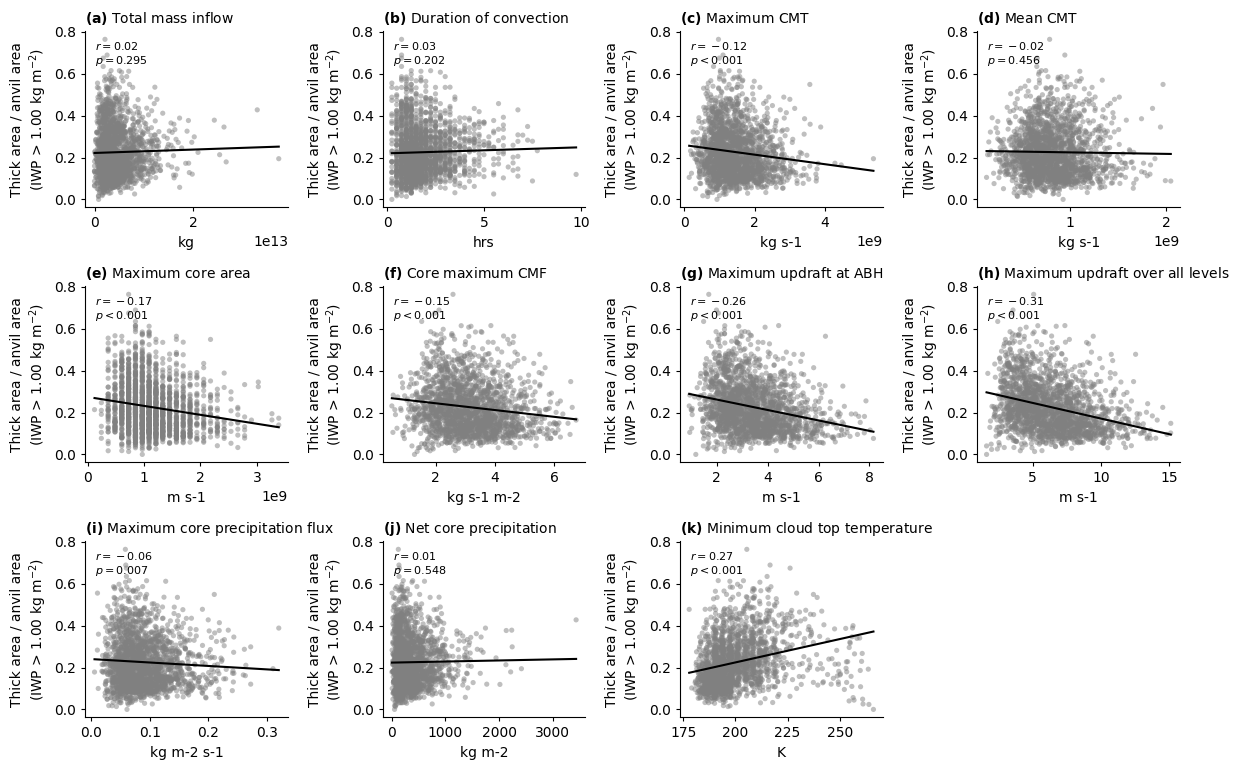

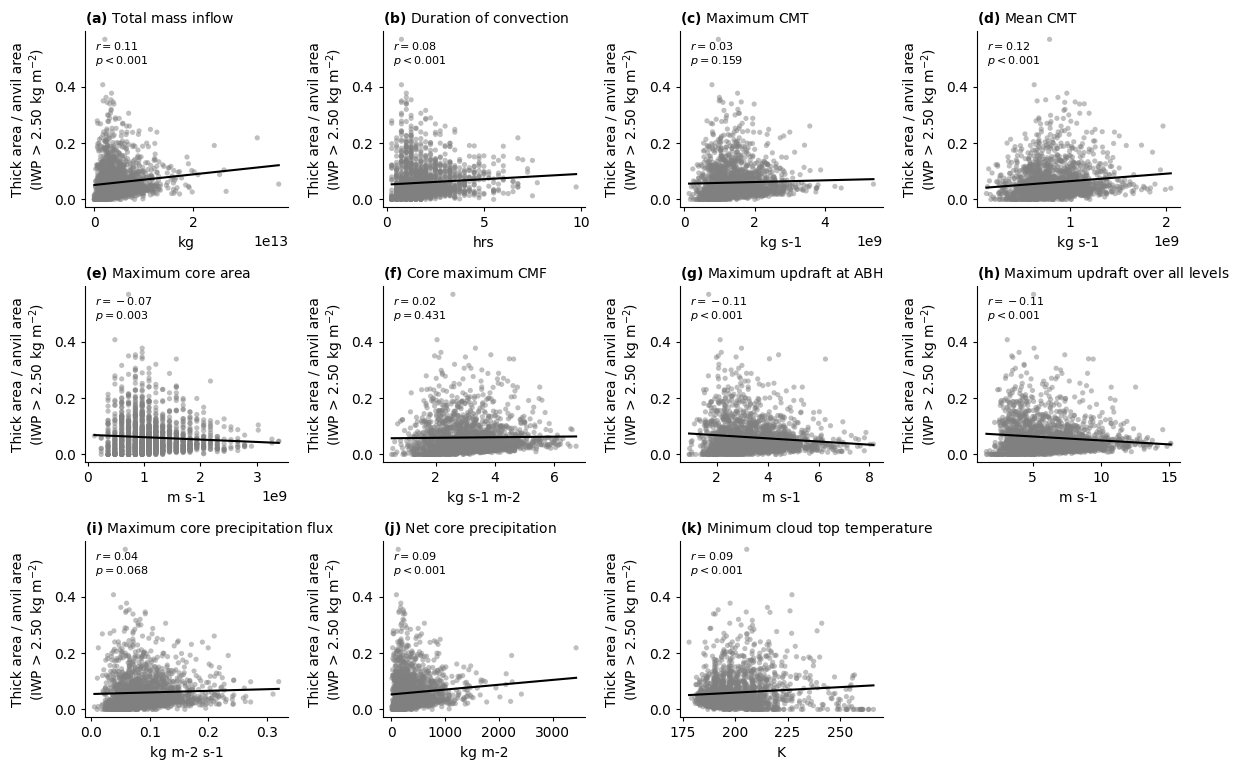

In [13]:
# thick area / anvil area vs each metric, one grid per threshold

for t, ratio in zip(thresholds, ratio_panels_s3):
    fig, axs = metric_scatter_grid(ds, metric_keys, ratio, f"Thick area / anvil area\n(IWP > {t:.2f} kg m$^{{-2}}$)")
    fig.savefig(extra_figs / f"fig_s4_thick_fraction_{str(t).replace('.', 'p')}.{ext}", bbox_inches='tight', dpi=dpi)
    plt.show()

### Section 5 — Distribution by metric quartile (boxplots)

One axis per metric; DCCs are split into quartiles of that metric (independently per axis), and the boxplots
show the distribution of the target quantity (maximum anvil area / total anvil area / thick fraction) within
each quartile.

In [14]:
def metric_boxplot_grid(ds, metric_keys, y, y_label, ncols=4, fs=10):
    nrows = int(np.ceil(len(metric_keys) / ncols))
    fig, axs = plt.subplots(nrows, ncols, figsize=(3 * ncols, 2.6 * nrows), layout='tight')
    axs = np.atleast_1d(axs).flatten()

    for i, key in enumerate(metric_keys):
        ax = axs[i]
        x = ds[key]
        valid = x.notnull() & y.notnull()
        _x, _y = x.where(valid, drop=True), y.where(valid, drop=True)

        box_data, box_labels = [], []
        if _x.size >= 4:
            edges = np.nanpercentile(_x.values, [0, 25, 50, 75, 100])
            edges[0] -= 1e-9
            for q in range(4):
                sel = (_x.values > edges[q]) & (_x.values <= edges[q + 1])
                box_data.append(_y.values[sel])
                box_labels.append(f"Q{q + 1}")

        ax.boxplot(box_data, labels=box_labels, showfliers=False)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.tick_params(direction='out', length=3, width=0.8)
        ax.set_ylabel(y_label, fontsize=fs)
        ax.set_title(rf"$\mathbf{{({letters[i]})}}$ {x.attrs.get('long_name', key)}", loc='left', fontsize=fs)

    for j in range(len(metric_keys), len(axs)):
        axs[j].axis('off')

    return fig, axs

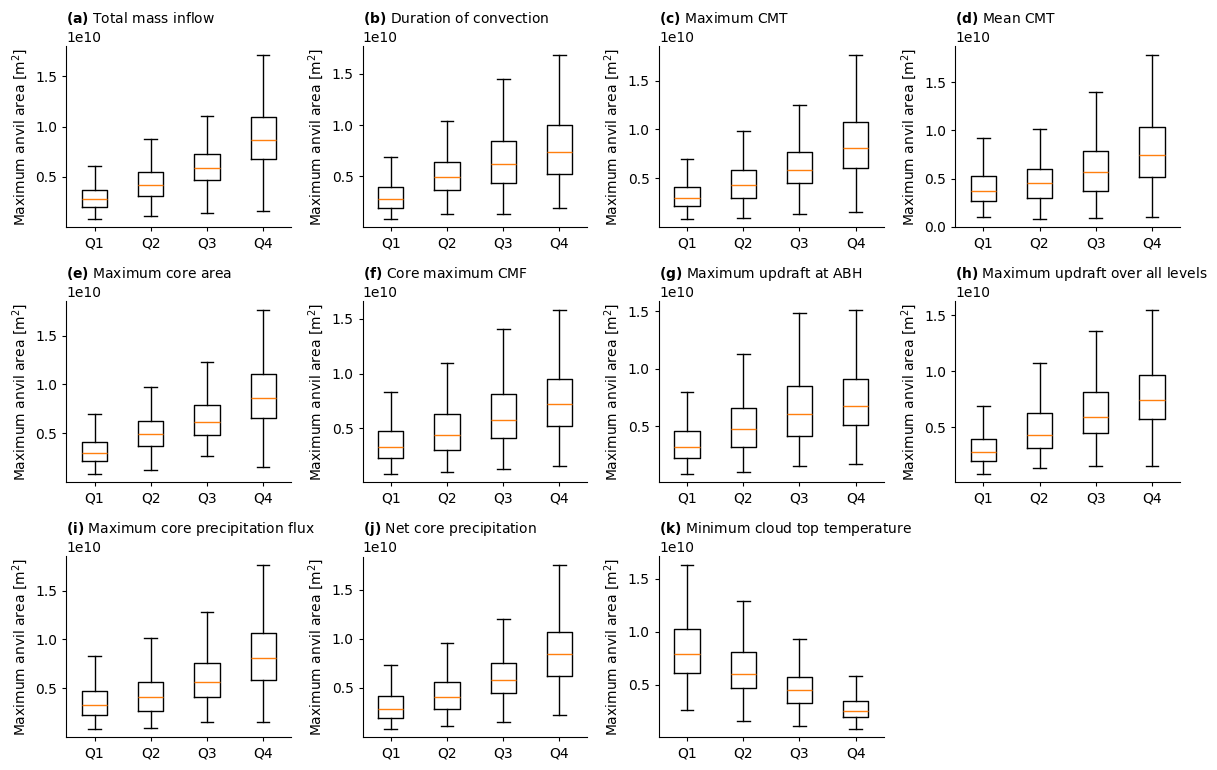

In [15]:
# maximum anvil area, by quartile of each metric

fig, axs = metric_boxplot_grid(ds, metric_keys, max_anvil_area, "Maximum anvil area [m$^2$]")
fig.savefig(extra_figs / f"fig_s5_max_anvil_area.{ext}", bbox_inches='tight', dpi=dpi)
plt.show()

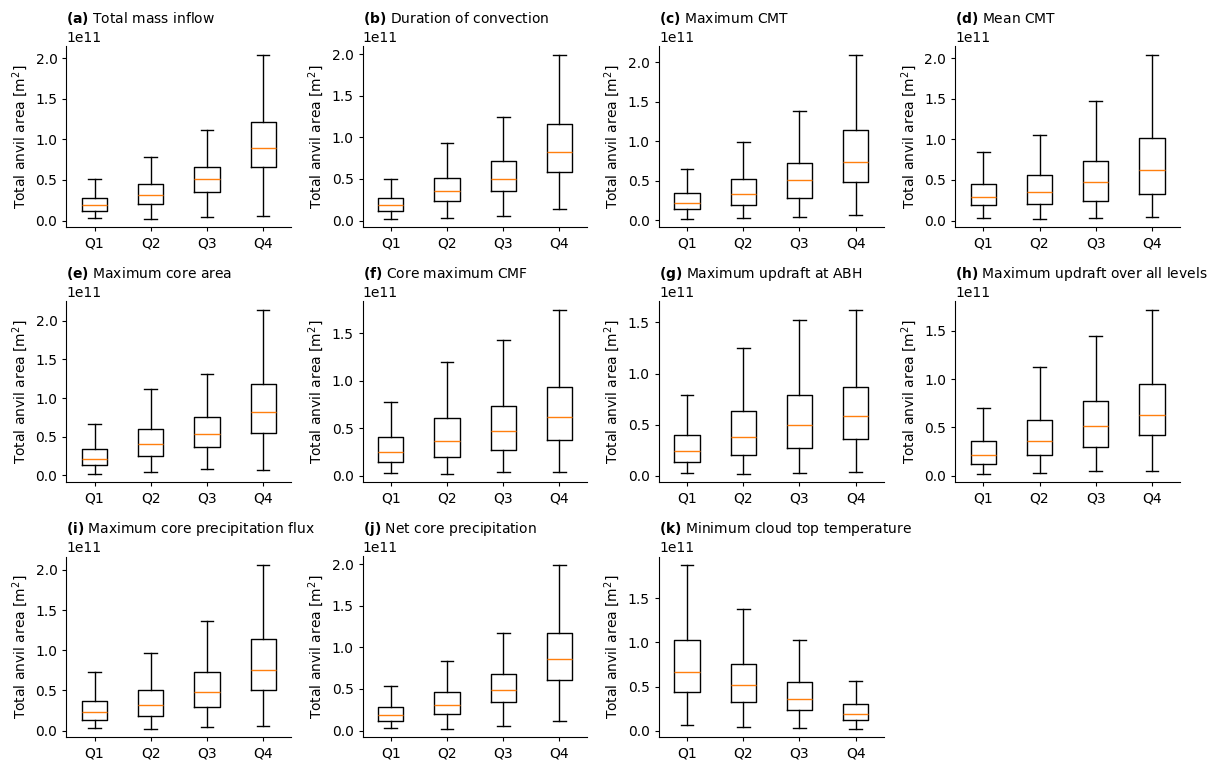

In [16]:
# total anvil area, by quartile of each metric

fig, axs = metric_boxplot_grid(ds, metric_keys, ds.total_anvil_area, "Total anvil area [m$^2$]")
fig.savefig(extra_figs / f"fig_s5_total_anvil_area.{ext}", bbox_inches='tight', dpi=dpi)
plt.show()

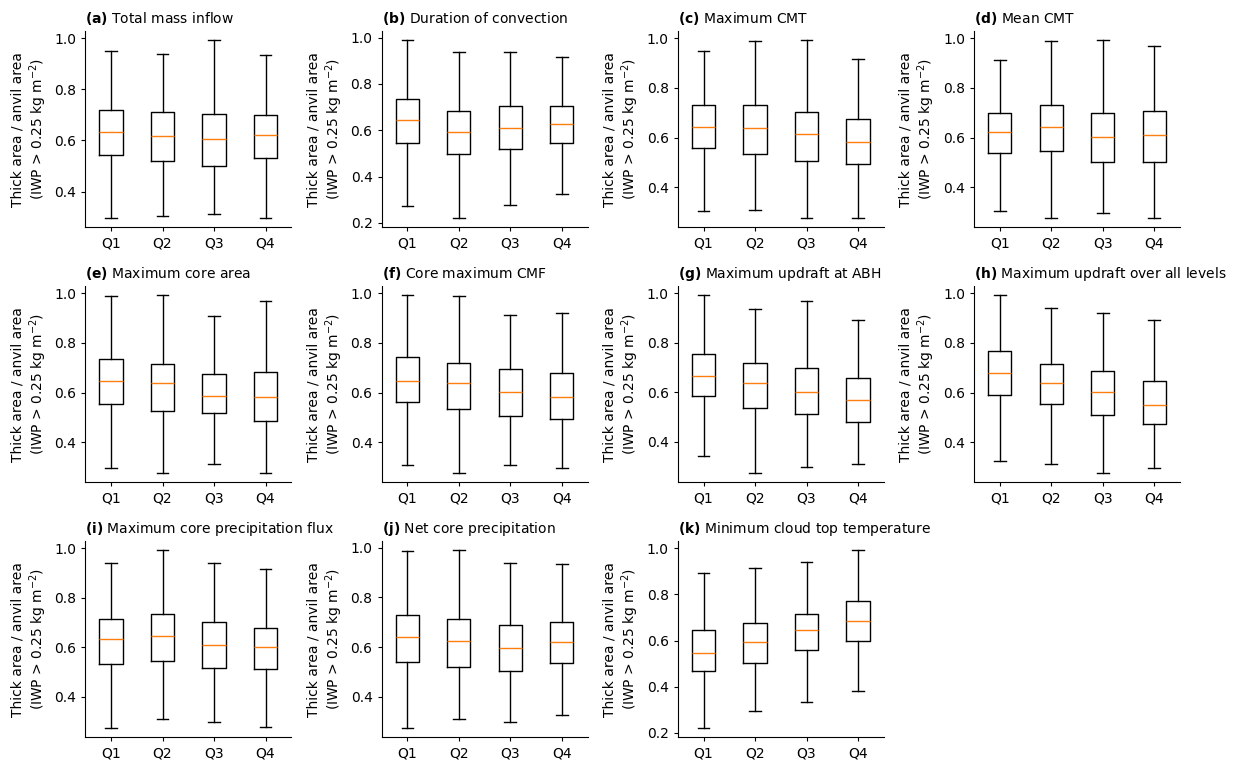

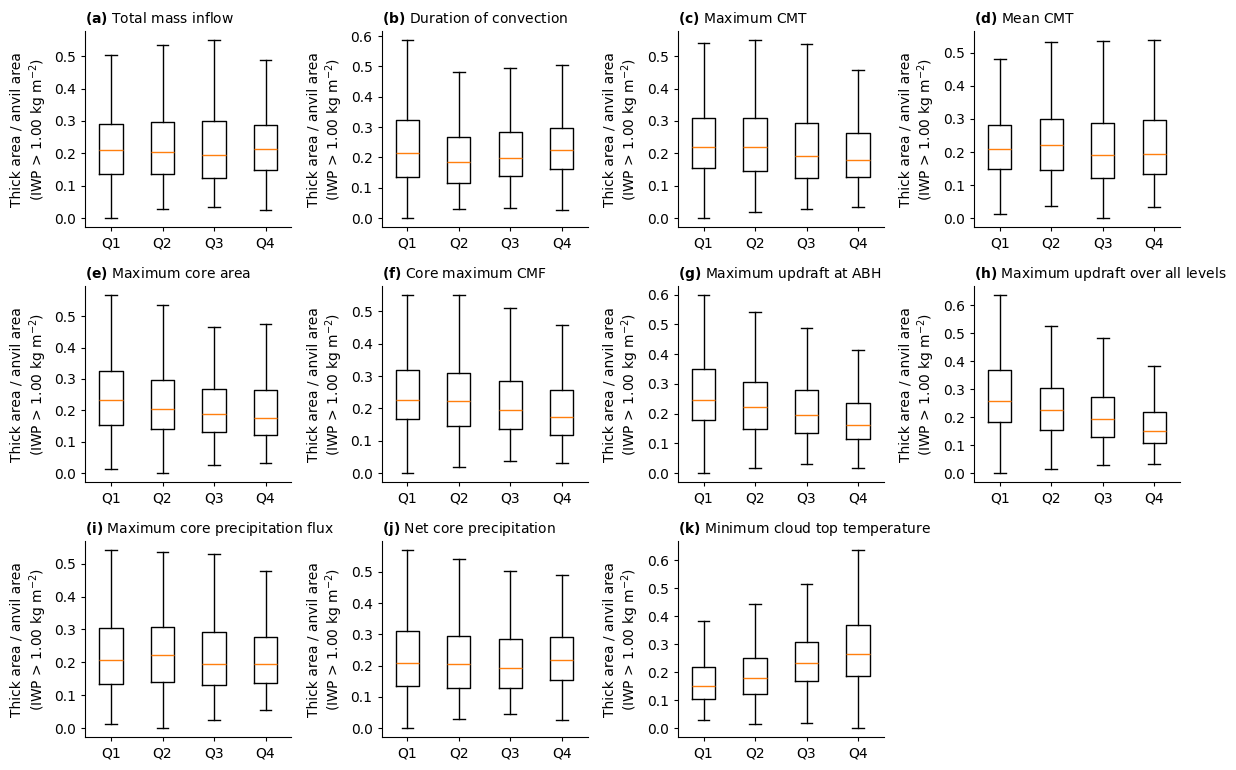

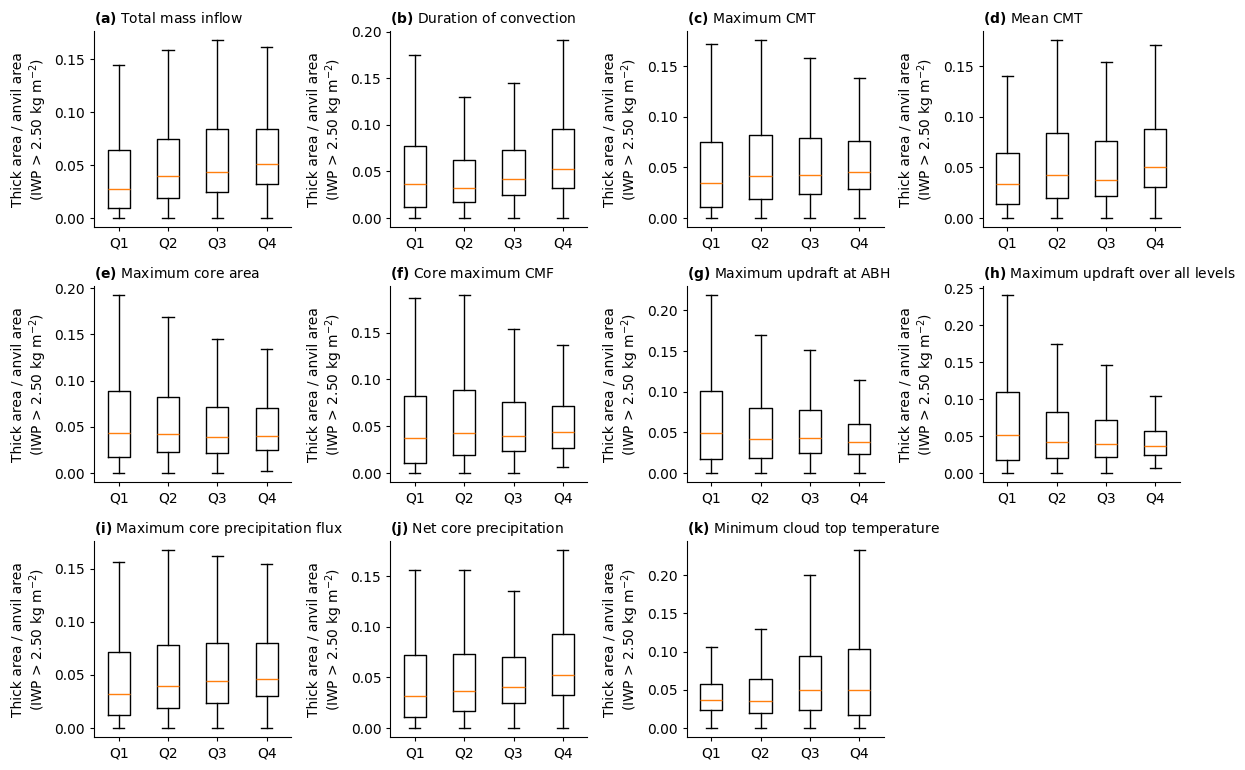

In [17]:
# thick area / anvil area, by quartile of each metric, one grid per threshold

for t, ratio in zip(thresholds, ratio_panels_s3):
    fig, axs = metric_boxplot_grid(ds, metric_keys, ratio, f"Thick area / anvil area\n(IWP > {t:.2f} kg m$^{{-2}}$)")
    fig.savefig(extra_figs / f"fig_s5_thick_fraction_{str(t).replace('.', 'p')}.{ext}", bbox_inches='tight', dpi=dpi)
    plt.show()